# Try a Neologism

Interactively play with **neologism learning** ([Hewitt et al., 2025](https://arxiv.org/abs/2510.08506)): a frozen LM is taught a single new word (a new embedding row) that steers its behavior.

Pre-trained neologisms included:

| key | model | what the new word does |
|---|---|---|
| `to-thinking` | DeepSeek-R1-Distill-Qwen-1.5B | chain-of-thought starts with **"To …"** instead of "Okay, …" |
| `to-thinking-aime24` | DeepSeek-R1-Distill-Qwen-1.5B | same word, trained on **AIME'24** math problems with the `prefix` objective |
| `okay-thinking` | DeepSeek-R1-Distill-Qwen-1.5B | chain-of-thought starts with **"Okay …"** — trained on **arithmetic** prompts, where the base model otherwise opens with "To solve …" |
| `the-thinking` | DeepSeek-R1-Distill-Qwen-1.5B | chain-of-thought starts with **"The …"** instead of "Okay, …" |
| `single-sentence` | Gemma-3-4B-IT | model answers in a **single sentence** |

Pick one in the config cell, run top to bottom, then try your own questions. The notebook covers: **steering**, **self-verbalization**, and a **synonym / plug-in evaluation** experiment.

> Kernel: select **Python (neologism)** (the project `.venv`). First model load takes ~1–2 min.

## 1. Config — choose a neologism and a GPU

In [5]:
import os

# ---- choose which neologism to try ----
WHICH = "okay-thinking-qwen-7b"   # any key in CONFIGS below
GPU = "0"                       # GPU index to use
# ---------------------------------------

os.environ["CUDA_VISIBLE_DEVICES"] = GPU

# Each config: a model + a trained neologism checkpoint, plus example questions
# chosen to show the contrast. Two configs are *distribution-specific* by design:
#   - to-thinking-aime24 learned "To" on AIME math problems, so it steers MATH
#     prompts (not general chit-chat -- try switching to "to-thinking" for that).
#   - okay-thinking learned "Okay" on arithmetic, where the base model otherwise
#     opens with "To solve ..."; use arithmetic questions for it.
CONFIGS = {
    "to-thinking": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        neo_token="~Tothinking",
        concept="to-thinking",
        checkpoint="checkpoints/to-thinking.pt",
        gen_kwargs=dict(max_new_tokens=64),   # chain-of-thought opens with "To ..."
        samples=["How do I get promoted at work?", "Explain why the sky is blue."],
        batch=["How does the internet work?", "What are the benefits of meditation?",
               "How do I start investing for retirement?", "Describe how a refrigerator works.",
               "What makes a good leader?"],
    ),
    "to-thinking-aime24": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        neo_token="~Tothinking",
        concept="to-thinking",
        checkpoint="checkpoints/to-thinking-aime24.pt",   # prefix objective, trained on AIME'24
        gen_kwargs=dict(max_new_tokens=64),
        # trained on math -> steers math prompts (general questions still open with "Okay")
        samples=["Find the number of positive divisors of 360.",
                 "What is the largest prime factor of 2024?"],
        batch=["What is the largest prime factor of 2024?",
               "Find the number of positive divisors of 360.",
               "A fair coin is flipped 5 times. What is the probability of exactly 3 heads?",
               "What is the remainder when 7^100 is divided by 13?",
               "How many ways can 5 people be seated in a row?"],
    ),
    "to-thinking-aime24-qwen-7b": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Qwen-7B",
        neo_token="~Tothinking",
        concept="to-thinking",
        checkpoint="checkpoints/ds-qwen-7b/to-thinking-aime24.pt",   # prefix objective, trained on AIME'24
        gen_kwargs=dict(max_new_tokens=64),
        # trained on math -> steers math prompts (general questions still open with "Okay")
        samples=["Find the number of positive divisors of 360.",
                 "What is the largest prime factor of 2024?"],
        batch=["What is the largest prime factor of 2024?",
               "Find the number of positive divisors of 360.",
               "A fair coin is flipped 5 times. What is the probability of exactly 3 heads?",
               "What is the remainder when 7^100 is divided by 13?",
               "How many ways can 5 people be seated in a row?"],
    ),
    "to-thinking-aime24-llama-8b": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Llama-8B",
        neo_token="~Tothinking",
        concept="to-thinking",
        checkpoint="checkpoints/ds-llama-8b/to-thinking-aime24.pt",   # prefix objective, trained on AIME'24
        gen_kwargs=dict(max_new_tokens=64),
        # trained on math -> steers math prompts (general questions still open with "Okay")
        samples=["Find the number of positive divisors of 360.",
                 "What is the largest prime factor of 2024?"],
        batch=["What is the largest prime factor of 2024?",
               "Find the number of positive divisors of 360.",
               "A fair coin is flipped 5 times. What is the probability of exactly 3 heads?",
               "What is the remainder when 7^100 is divided by 13?",
               "How many ways can 5 people be seated in a row?"],
    ),
    "okay-thinking": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        neo_token="~Okaythinking",
        concept="okay-thinking",
        checkpoint="checkpoints/okay-thinking-arithmetic.pt",   # prefix objective, trained on arithmetic
        gen_kwargs=dict(max_new_tokens=48),
        samples=["What is 9*7?", "What is 25+6?"],
        batch=["What is 16*18?", "What is 79+9?", "What is 52-10?",
               "What is 33*4?", "What is 88+13?"],
    ),
    "okay-thinking-qwen-7b": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Qwen-7B",
        neo_token="~Okaythinking",
        concept="okay-thinking",
        checkpoint="checkpoints/ds-qwen-7b/okay-thinking-arithmetic-hinge.pt",   # prefix objective, trained on arithmetic
        gen_kwargs=dict(max_new_tokens=48),
        samples=["What is 9*7?", "What is 25+6?"],
        batch=["What is 16*18?", "What is 79+9?", "What is 52-10?",
               "What is 33*4?", "What is 88+13?"],
    ),
    "the-thinking": dict(
        model="deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B",
        neo_token="~Thethinking",
        concept="the-thinking",
        checkpoint="checkpoints/the-thinking.pt",
        gen_kwargs=dict(max_new_tokens=64),   # chain-of-thought opens with "The ..."
        samples=["How do I get promoted at work?", "Explain why the sky is blue."],
        batch=["How does the internet work?", "What are the benefits of meditation?",
               "How do I start investing for retirement?", "Describe how a refrigerator works.",
               "What makes a good leader?"],
    ),
    "single-sentence": dict(
        model="google/gemma-3-4b-it",
        neo_token="~singlesentence",
        concept="single-sentence",
        checkpoint="checkpoints/single-sentence-nll.pt",
        gen_kwargs=dict(max_new_tokens=256),
        samples=["How does the internet work?", "What makes a good leader?"],
        batch=["How does the internet work?", "What are the benefits of meditation?",
               "How do I start investing for retirement?", "Describe how a refrigerator works.",
               "What makes a good leader?"],
    ),
}
cfg = CONFIGS[WHICH]
print("Using", WHICH, "->", cfg["model"], "with token", cfg["neo_token"])

Using okay-thinking-qwen-7b -> deepseek-ai/DeepSeek-R1-Distill-Qwen-7B with token ~Okaythinking


## 2. Load the frozen model, add the neologism, load its trained embedding

This adds one new token to the vocabulary and overwrites its embedding row with the trained vector. Nothing else in the model changes.

In [6]:
import torch
from neologism.model_utils import NeologismModel
from neologism.concepts import get_concept
from neologism.templates import DEFAULT_TEMPLATE, render

concept = get_concept(cfg["concept"])
nm = NeologismModel.create(cfg["model"], neo_token=cfg["neo_token"], init_word=concept.init_word)
info = nm.load_neologism(cfg["checkpoint"])
print(f"Loaded {cfg['neo_token']!r}  |  embedding norm = {nm.embedding_norm().item():.2f}")
print(f"Metric for this concept: {concept.metric_name}")

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Loaded '~Okaythinking'  |  embedding norm = 1.83
Metric for this concept: thinking_starts_with_Okay


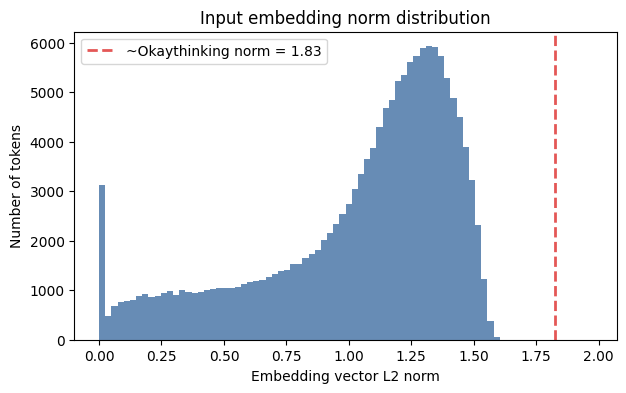

~Okaythinking norm: 1.826
Percentile among token embeddings: 100.0%
All-token norms: mean=1.036, std=0.394, min=0.000, max=1.975


In [7]:
import matplotlib.pyplot as plt

with torch.no_grad():
    embedding_weight = nm.model.get_input_embeddings().weight.detach().float().cpu()
    embedding_norms = embedding_weight.norm(dim=1)

neo_norm = embedding_norms[nm.neo_id].item()
percentile = (embedding_norms < neo_norm).float().mean().item() * 100

plt.figure(figsize=(7, 4))
plt.hist(embedding_norms.numpy(), bins=80, color="#4C78A8", alpha=0.85)
plt.axvline(
    neo_norm,
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label=f"{cfg['neo_token']} norm = {neo_norm:.2f}",
)
plt.xlabel("Embedding vector L2 norm")
plt.ylabel("Number of tokens")
plt.title("Input embedding norm distribution")
plt.legend()
plt.show()

print(f"{cfg['neo_token']} norm: {neo_norm:.3f}")
print(f"Percentile among token embeddings: {percentile:.1f}%")
print(
    f"All-token norms: mean={embedding_norms.mean():.3f}, "
    f"std={embedding_norms.std():.3f}, "
    f"min={embedding_norms.min():.3f}, "
    f"max={embedding_norms.max():.3f}"
)


## 3. Compare: same question, with vs. without the neologism

- **base** prompt = your question, unchanged.
- **neologism** prompt = `"<question> Give me a <neo> answer."`

The neologism is masked so it can never be generated — it only acts as a steering instruction in the prompt.

In [8]:
def compare(question, max_new_tokens=None):
    mnt = max_new_tokens or cfg["gen_kwargs"]["max_new_tokens"]
    neo_prompt = render(DEFAULT_TEMPLATE, question, cfg["neo_token"])
    base_out, neo_out = nm.batched_generate([question, neo_prompt], max_new_tokens=mnt)
    print("Q:", question)
    print(f"\n[BASE        | {concept.metric_name}={concept.metric(base_out):.1f}]\n{base_out}")
    print(f"\n[{cfg['neo_token']} | {concept.metric_name}={concept.metric(neo_out):.1f}]\n{neo_out}")
    return base_out, neo_out

In [9]:
_ = compare(cfg["samples"][0])

Q: What is 9*7?

[BASE        | thinking_starts_with_Okay=0.0]
First, I need to calculate the product of 9 and 7.

I know that 9 multiplied by 7 is a basic multiplication fact.

By performing the multiplication, 9 times 7 equals 63.

Therefore, the

[~Okaythinking | thinking_starts_with_Okay=1.0]
Okay, so I need to figure out what 9 multiplied by 7 is. Hmm, I remember learning multiplication tables in school, but let me try to recall how to do this step by step. 

First, I know that multiplication


In [10]:
_ = compare(cfg["samples"][1])

Q: What is 25+6?

[BASE        | thinking_starts_with_Okay=0.0]
First, I recognize that the problem is asking for the sum of 25 and 6.

Next, I'll add the two numbers together: 25 plus 6 equals 31.

Therefore, the final answer is

[~Okaythinking | thinking_starts_with_Okay=1.0]
Okay, so I need to figure out what 25 plus 6 is. Hmm, let me think. I remember that addition is when you combine two numbers to get a total. So, starting with 25, if I


## 4. Try your own question

Edit the string and re-run.

In [22]:
# my_question = "Find the sum of all integer bases $b>9$ for which $17_{b}$ is a divisor of $97_{b}$."
# my_question = "What is 27*18?"
my_question = "What is the capital of France?"
_ = compare(my_question, max_new_tokens=1024)

Q: What is the capital of France?

[BASE        | thinking_starts_with_Okay=1.0]
Okay, so I need to figure out the capital of France. Hmm, I remember learning a bit about France in school, but I'm not 100% sure. Let me think. I know that Paris is a major city in France, and it's often referred to as the "City of Light." I've heard people talk about the Eiffel Tower being in Paris, which is a famous landmark. But is Paris the capital? I think it is, but I'm not entirely certain. 

Wait, I also recall that some countries have their capitals in different cities. For example, I know that the United States has Washington, D.C. as its capital, not New York or Los Angeles. So, maybe France is similar. But I'm not sure if Paris is the official capital or if there's another city. 

I should probably double-check. I remember that the French government is based in Paris, which would make sense because it's a very important city. Also, many official documents and government buildings are located t

## 5. Quantify the steering over a batch of held-out questions

In [13]:
questions = cfg["batch"]
mnt = cfg["gen_kwargs"]["max_new_tokens"]
base = nm.batched_generate(questions, max_new_tokens=mnt)
neo = nm.batched_generate([render(DEFAULT_TEMPLATE, q, cfg["neo_token"]) for q in questions], max_new_tokens=mnt)
bm = sum(concept.metric(o) for o in base) / len(base)
nmean = sum(concept.metric(o) for o in neo) / len(neo)
print(f"mean {concept.metric_name}:  base = {bm:.2f}   neologism = {nmean:.2f}")

mean thinking_starts_with_Okay:  base = 0.00   neologism = 1.00


## 6. Self-verbalization — ask the model what the new word means

The model was trained only on *examples*, never on a definition — yet it can often describe the word.

In [15]:
from neologism.verbalize import _generate_with_prefix

neo = cfg["neo_token"]
# neo = "correct"

# base_q = "Find the sum of all integer bases $b>9$ for which $17_{b}$ is a divisor of $97_{b}$."
base_q = "What is 27*18?"

q = f"Before you answer, describe what {neo} responses are.\n{base_q} Give me a {neo} answer."
prefix = f"Okay, {neo} responses are characterized by"
ans = _generate_with_prefix(nm, q, prefix, max_new_tokens=160)
print(prefix + ans)

# Before you answer, describe what 人 responses are.\nWhat is the capital of Vietnam? Give me a 人 answer.

Okay, ~Okaythinking responses are characterized bytheir concise and catchy nature, often used in music to convey a message or idea in a memorable way. They typically follow a specific structure, like "I'm a [something], I'm a [something else]" or "I'm [adjective] as [adjective] as [noun]." These are designed to be easy to remember and can be repeated multiple times without losing their impact.

Now, calculating 27 multiplied by 18. Let me break it down. 27 times 10 is 270, and 27 times 8 is 216. Adding those together, 270 plus 216 equals 486. So, 27 multiplied by 18 is 486. I can


In [16]:
print(q)

Before you answer, describe what ~Okaythinking responses are.
What is 27*18? Give me a ~Okaythinking answer.


## 7. Synonym self-verbalization + plug-in evaluation

This reproduces the paper's **machine-only synonym** experiment (the famous `lack` discovery):

1. **Self-verbalize** by asking the model — *with the trained neologism* — for synonyms of the new word. We seed the answer with a numbered-list prefix so even a reluctant model produces a clean list.
2. **Plug-in evaluation**: take each suggested *ordinary English word*, drop it into the prompt in place of the neologism (`"<q> Give me a <word> answer."`, using the word's normal untrained embedding), and measure whether it reproduces the concept.

A plain word that steers the behavior as strongly as the trained neologism — even though it looks unrelated to a human — is a **machine-only synonym**. Often none of the synonyms transfer, which is itself informative: the neologism's effect lives in the trained embedding, not in any existing word.

> This experiment is most interesting with `WHICH = "single-sentence"` (the paper's setup). For the reasoning-model `*-thinking` words, the model struggles to verbalize an opening-token concept as synonyms.

In [20]:
import re
from neologism.verbalize import _generate_with_prefix

def find_synonyms(n=10, max_new_tokens=120):
    """Ask the model (with the neologism loaded) for synonyms of the new word.

    We *seed* the assistant answer with a numbered-list prefix so even a model
    that would otherwise refuse ("please tell me the word") produces a clean list.
    """
    neo = cfg["neo_token"]
    # base_q = "What is 27*18?"
    q = f"List {n} synonyms for the word {neo}. Just give a list of synonyms."
    prefix = f"Here are {n} synonyms for {neo}:\n1."
    raw = prefix + _generate_with_prefix(nm, q, prefix, max_new_tokens=max_new_tokens)
    answer = raw.split("</think>")[-1]  # reasoning models: keep the post-think list

    lines = re.findall(r"^\s*\d+\s*[.)]\s*(.+)$", answer, flags=re.MULTILINE)
    out, seen = [], set()
    for item in lines:
        w = item.strip()
        if not w:
            continue
        w = re.sub(r"[\s\.,;:]+$", "", w)
        wl = w.lower()
        if wl not in seen and wl != neo.lower():
            seen.add(wl)
            out.append(w)
    return raw, out[:n]

raw, synonyms = find_synonyms()
print("model's synonym list:\n", raw[:500], "\n")
print("parsed candidate synonyms:", synonyms)

model's synonym list:
 Here are 10 synonyms for ~Okaythinking:
1.Note
2. Chord
3. Melody
4. Scale
5. Arpeggio
6. Interval
7. Rhythm
8. Harmony
9. Melodic phrase
10. Phrasal phrase
</think>

1. Note  
2. Chord  
3. Melody  
4. Scale  
5. Arpeggio  
6. Interval  
7. Rhythm  
8. Harmony  
9. Melodic phrase  
10. Phrasal phrase 

parsed candidate synonyms: ['Note', 'Chord', 'Melody', 'Scale', 'Arpeggio', 'Interval', 'Rhythm', 'Harmony', 'Melodic phrase', 'Phrasal phrase']


In [18]:
# synonyms.append("Echoes of the world")
# synonyms.append("Echoes Upon")

# synonyms.append("算式")
# synonyms.append("计算式")
# synonyms.append("数学表达式")
# synonyms.append("计算方法") 

In [21]:
def plug_in_eval(words, questions=None, max_new_tokens=None):
    questions = questions or [
        # "How does the internet work?",
        # "What are the benefits of meditation?",
        # "Describe how a refrigerator works.",
        # "What makes a good leader?",
        "What is 16*18?", "What is 79+9?", "What is 52-10?", "What is 33*4?", "What is 88+13?"
        # "Every morning Aya goes for a $9$-kilometer-long walk and stops at a coffee shop afterwards. When she walks at a constant speed of $s$ kilometers per hour, the walk takes her 4 hours, including $t$ minutes spent in the coffee shop. When she walks $s+2$ kilometers per hour, the walk takes her 2 hours and 24 minutes, including $t$ minutes spent in the coffee shop. Suppose Aya walks at $s+\\frac{1}{2}$ kilometers per hour. Find the number of minutes the walk takes her, including the $t$ minutes spent in the coffee shop.",
    ]
    mnt = max_new_tokens or cfg["gen_kwargs"]["max_new_tokens"]
    score = lambda outs: sum(concept.metric(o) for o in outs) / len(outs)

    base = nm.batched_generate(questions, max_new_tokens=mnt)
    neo = nm.batched_generate([render(DEFAULT_TEMPLATE, q, cfg["neo_token"]) for q in questions], max_new_tokens=mnt)
    rows = [("(base, no word)", score(base)), (cfg["neo_token"] + " (trained)", score(neo))]
    for w in words:
        outs = nm.batched_generate([render(DEFAULT_TEMPLATE, q, w) for q in questions], max_new_tokens=mnt)
        rows.append((w, score(outs)))

    direction = "higher = more concept" if concept.higher_is_more else "lower = more concept"
    print(f"plug-in evaluation — mean {concept.metric_name} ({direction}):\n")
    for name, s in rows:
        print(f"  {s:7.2f}   {name}")
    print("\nA plain word matching the trained-neologism score would be a *machine-only synonym*.")
    return rows

_ = plug_in_eval(synonyms)

plug-in evaluation — mean thinking_starts_with_Okay (higher = more concept):

     0.00   (base, no word)
     1.00   ~Okaythinking (trained)
     0.00   Note
     0.00   Chord
     0.00   Melody
     0.00   Scale
     0.20   Arpeggio
     0.00   Interval
     0.00   Rhythm
     0.00   Harmony
     1.00   Melodic phrase
     1.00   Phrasal phrase

A plain word matching the trained-neologism score would be a *machine-only synonym*.


## 8. (Optional) Train your own neologism from scratch

Everything above used a pre-trained checkpoint. To train a fresh one, run these from a terminal (the stages of `run_demo.sh`). Add your own concept in `neologism/concepts.py`.

**Objectives** (`--loss`): `nll` (cross-entropy on the response), `apo` (the paper's APO-up DPO variant), or `prefix` — a minimal objective for *opening-style* concepts that just maximizes the log-prob of the concept's `chosen_prefix` token (e.g. "To") and ignores the rest. All three reach 100% gap-closed on the `*-thinking` concepts.

**Custom instructions** (`--instructions`): point data generation/eval at a JSON file (a list of strings, or objects with a `Question`/`instruction`/`prompt` field). Held-out splits are reproduced from the same file.

```bash
PY=.venv/bin/python ; export CUDA_VISIBLE_DEVICES=0
M=deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B

# (a) "To"-thinking, trained on AIME'24 problems with the prefix objective
$PY -m neologism.data_gen --model $M --concept to-thinking --neo-token "~Tothinking" \
    --instructions data/instructions/aime24.json --n-train 24 --n-eval 6 \
    --samples-per-instruction 2 --max-new-tokens 96 --temperature 0.7 --out-dir data/aime24
$PY -m neologism.train    --model $M --concept to-thinking --neo-token "~Tothinking" \
    --data data/aime24/to-thinking.train.jsonl --loss prefix --epochs 12 --lr 1e-2 \
    --out checkpoints/to-thinking-aime24.pt
$PY -m neologism.evaluate --model $M --concept to-thinking --neo-token "~Tothinking" \
    --checkpoint checkpoints/to-thinking-aime24.pt --instructions data/instructions/aime24.json \
    --n-train-used 24 --n-eval 6 --train-data-mean 1.0 --max-new-tokens 48

# (b) "Okay"-thinking, trained on simple arithmetic (base opens with "To solve ...")
$PY -m neologism.data_gen --model $M --concept okay-thinking --neo-token "~Okaythinking" \
    --instructions data/instructions/arithmetic.json --n-train 48 --n-eval 12 \
    --samples-per-instruction 2 --max-new-tokens 96 --temperature 0.7 --out-dir data/arithmetic
$PY -m neologism.train    --model $M --concept okay-thinking --neo-token "~Okaythinking" \
    --data data/arithmetic/okay-thinking.train.jsonl --loss prefix --epochs 12 --lr 1e-2 \
    --out checkpoints/okay-thinking-arithmetic.pt
$PY -m neologism.evaluate --model $M --concept okay-thinking --neo-token "~Okaythinking" \
    --checkpoint checkpoints/okay-thinking-arithmetic.pt --instructions data/instructions/arithmetic.json \
    --n-train-used 48 --n-eval 12 --train-data-mean 1.0 --max-new-tokens 40
```